# EXPT NO: 8 — Generation of Synthetic Images using a Generative Adversarial Network (GAN)
  Name: Swathi v
  
  Roll No: 24BAD122

## PART A: Dataset Preparation

In [4]:

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))
tf.random.set_seed(42); np.random.seed(42)
print("SWAthi v 24BAD122")


TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
SWAthi v 24BAD122


Train shape : (60000, 28, 28) | Test shape: (10000, 28, 28)
Image dims  : (28, 28) | dtype: uint8
Pixel range : min = 0 , max = 255


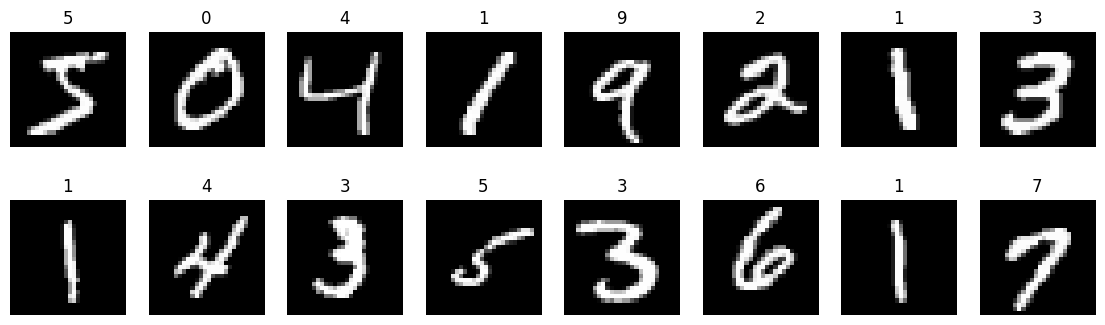

In [ ]:
# Load MNIST


(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()

# Explore
print("Train shape :", x_train.shape, "| Test shape:", x_test.shape)
print("Image dims  :", x_train.shape[1:], "| dtype:", x_train.dtype)
print("Pixel range : min =", x_train.min(), ", max =", x_train.max())

# Display sample images
fig, axes = plt.subplots(2, 8, figsize=(14, 4))
for i, ax in enumerate(axes.flat):
    ax.imshow(x_train[i], cmap="gray"); ax.set_title(int(y_train[i])); ax.axis("off")

plt.show()

In [ ]:
# Normalize to [-1, 1] (matches tanh output of Generator) and reshape to (N, 28, 28, 1)
x_train_n = (x_train.astype("float32") - 127.5) / 127.5
x_train_n = x_train_n.reshape(-1, 28, 28, 1)
print("After normalization:", x_train_n.shape, "| range:", x_train_n.min(), "to", x_train_n.max())

BUFFER_SIZE = x_train_n.shape[0]
BATCH_SIZE = 128
train_ds = (tf.data.Dataset.from_tensor_slices(x_train_n)
            .shuffle(BUFFER_SIZE).batch(BATCH_SIZE, drop_remainder=True)
            .prefetch(tf.data.AUTOTUNE))
print("Batches per epoch:", len(train_ds))
for b in train_ds.take(1): print("One batch shape:", b.shape)

After normalization: (60000, 28, 28, 1) | range: -1.0 to 1.0
Batches per epoch: 468
One batch shape: (128, 28, 28, 1)


## PART B: Implementing the Generator and Discriminator

In [ ]:
LATENT_DIM = 100

def build_generator():
    return models.Sequential([
        layers.Input(shape=(LATENT_DIM,)),
        layers.Dense(7*7*256, use_bias=False),
        layers.BatchNormalization(),
        layers.LeakyReLU(0.2),
        layers.Reshape((7, 7, 256)),
        layers.Conv2DTranspose(128, 5, strides=1, padding="same", use_bias=False),
        layers.BatchNormalization(),
        layers.LeakyReLU(0.2),
        layers.Conv2DTranspose(64, 5, strides=2, padding="same", use_bias=False),   # 14x14
        layers.BatchNormalization(),
        layers.LeakyReLU(0.2),
        layers.Conv2DTranspose(1, 5, strides=2, padding="same", activation="tanh"),  # 28x28x1
    ], name="Generator")

def build_discriminator():
    return models.Sequential([
        layers.Input(shape=(28, 28, 1)),
        layers.Conv2D(64, 5, strides=2, padding="same"),
        layers.LeakyReLU(0.2),
        layers.Dropout(0.3),
        layers.Conv2D(128, 5, strides=2, padding="same"),
        layers.LeakyReLU(0.2),
        layers.Dropout(0.3),
        layers.Flatten(),
        layers.Dense(1),    # logit (real vs fake)
    ], name="Discriminator")

generator = build_generator()
discriminator = build_discriminator()
generator.summary()
discriminator.summary()

Model: "Generator"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_2 (Dense)                 │ (None, 12544)          │     1,254,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 12544)          │        50,176 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_5 (LeakyReLU)       │ (None, 12544)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape_1 (Reshape)             │ (None, 7, 7, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_3              │ (None, 7, 7, 128)      │       819,200 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 7, 7, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_6 (LeakyReLU)       │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_4              │ (None, 14, 14, 64)     │       204,800 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_7 (LeakyReLU)       │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_5              │ (None, 28, 28, 1)      │         1,601 │
│ (Conv2DTranspose)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,330,945 (8.89 MB)

 Trainable params: 2,305,473 (8.79 MB)

 Non-trainable params: 25,472 (99.50 KB)

Model: "Discriminator"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 14, 14, 64)     │         1,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_8 (LeakyReLU)       │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 7, 7, 128)      │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_9 (LeakyReLU)       │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │         6,273 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 212,865 (831.50 KB)

 Trainable params: 212,865 (831.50 KB)

 Non-trainable params: 0 (0.00 B)

Model: "GAN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Generator (Sequential)          │ (None, 28, 28, 1)      │     2,330,945 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Discriminator (Sequential)      │ (None, 1)              │       212,865 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,543,810 (9.70 MB)

 Trainable params: 2,518,338 (9.61 MB)

 Non-trainable params: 25,472 (99.50 KB)

Generator output shape: (1, 28, 28, 1) | D score: -0.0006647526752203703


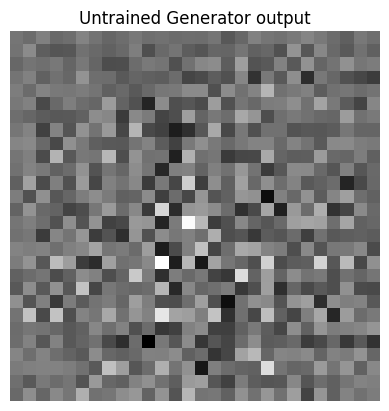

In [ ]:
# Loss functions and optimizers
bce = tf.keras.losses.BinaryCrossentropy(from_logits=True)

def discriminator_loss(real_out, fake_out):
    real_loss = bce(tf.ones_like(real_out), real_out)    # real -> 1
    fake_loss = bce(tf.zeros_like(fake_out), fake_out)   # fake -> 0
    return real_loss + fake_loss

def generator_loss(fake_out):
    return bce(tf.ones_like(fake_out), fake_out)         # Generator wants fake -> 1

g_opt = tf.keras.optimizers.Adam(2e-4, beta_1=0.5)
d_opt = tf.keras.optimizers.Adam(2e-4, beta_1=0.5)

# Combined GAN model (Generator -> Discriminator), shown for architecture/summary
gan = models.Sequential([generator, discriminator], name="GAN")
gan.summary()

# Sanity check: untrained generator output
z = tf.random.normal([1, LATENT_DIM])
img = generator(z, training=False)
print("Generator output shape:", img.shape, "| D score:", float(discriminator(img, training=False)))
plt.imshow(img[0, :, :, 0], cmap="gray"); plt.title("Untrained Generator output"); plt.axis("off"); plt.show()

## PART C: GAN Training and Performance Monitoring

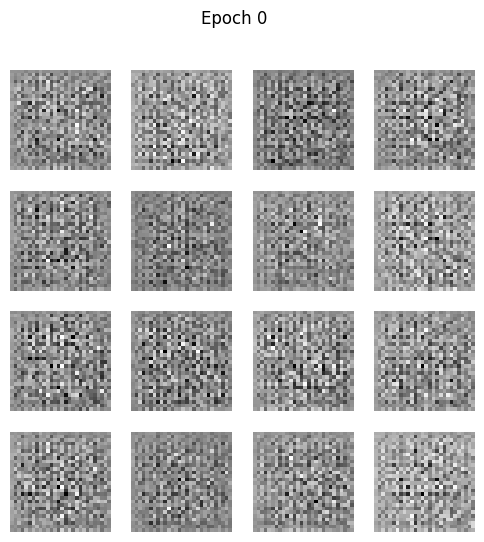

Epoch 01/30 | G loss: 0.7225 | D loss: 1.2923 | 20.5s


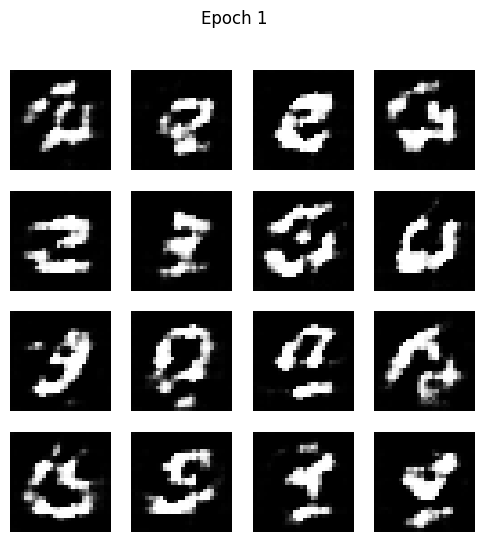

Epoch 02/30 | G loss: 0.7657 | D loss: 1.3163 | 12.9s
Epoch 03/30 | G loss: 0.8030 | D loss: 1.2862 | 13.1s
Epoch 04/30 | G loss: 0.7748 | D loss: 1.3204 | 13.2s
Epoch 05/30 | G loss: 0.7673 | D loss: 1.3248 | 13.3s


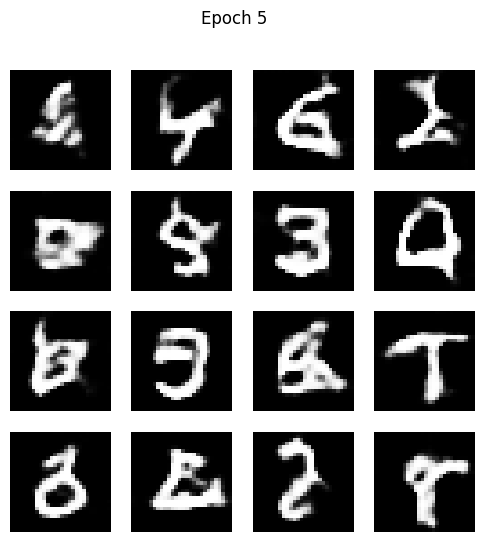

Epoch 06/30 | G loss: 0.7751 | D loss: 1.3183 | 13.4s
Epoch 07/30 | G loss: 0.7760 | D loss: 1.3146 | 13.6s
Epoch 08/30 | G loss: 0.7878 | D loss: 1.3085 | 13.7s
Epoch 09/30 | G loss: 0.7930 | D loss: 1.3059 | 13.8s
Epoch 10/30 | G loss: 0.8004 | D loss: 1.3014 | 13.8s


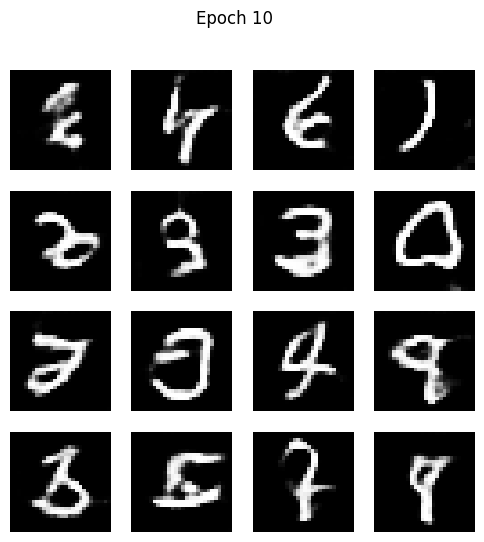

Epoch 11/30 | G loss: 0.8037 | D loss: 1.2990 | 13.9s
Epoch 12/30 | G loss: 0.8071 | D loss: 1.2953 | 14.5s
Epoch 13/30 | G loss: 0.8078 | D loss: 1.2981 | 15.3s
Epoch 14/30 | G loss: 0.8020 | D loss: 1.3040 | 14.2s
Epoch 15/30 | G loss: 0.8026 | D loss: 1.3045 | 14.8s
Epoch 16/30 | G loss: 0.7997 | D loss: 1.3087 | 14.3s
Epoch 17/30 | G loss: 0.8104 | D loss: 1.2992 | 14.3s
Epoch 18/30 | G loss: 0.7882 | D loss: 1.3142 | 14.3s
Epoch 19/30 | G loss: 0.8068 | D loss: 1.3097 | 14.3s
Epoch 20/30 | G loss: 0.7911 | D loss: 1.3132 | 14.3s


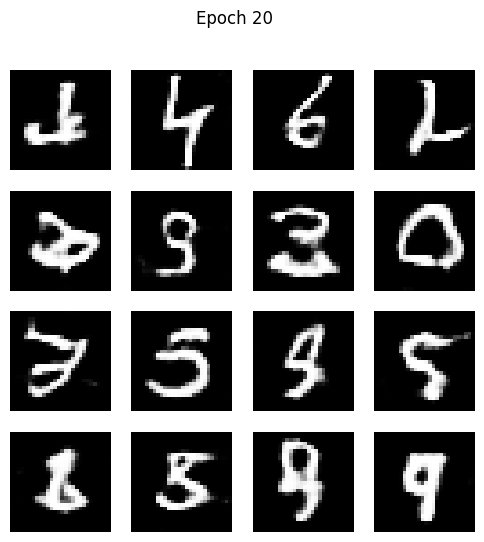

Epoch 21/30 | G loss: 0.7912 | D loss: 1.3167 | 14.3s
Epoch 22/30 | G loss: 0.7996 | D loss: 1.3119 | 14.4s
Epoch 23/30 | G loss: 0.7862 | D loss: 1.3199 | 14.4s
Epoch 24/30 | G loss: 0.8035 | D loss: 1.3097 | 14.4s
Epoch 25/30 | G loss: 0.7839 | D loss: 1.3210 | 14.4s
Epoch 26/30 | G loss: 0.7961 | D loss: 1.3165 | 14.5s
Epoch 27/30 | G loss: 0.7851 | D loss: 1.3203 | 14.5s
Epoch 28/30 | G loss: 0.7947 | D loss: 1.3181 | 14.5s
Epoch 29/30 | G loss: 0.7872 | D loss: 1.3200 | 14.5s
Epoch 30/30 | G loss: 0.8011 | D loss: 1.3122 | 14.5s


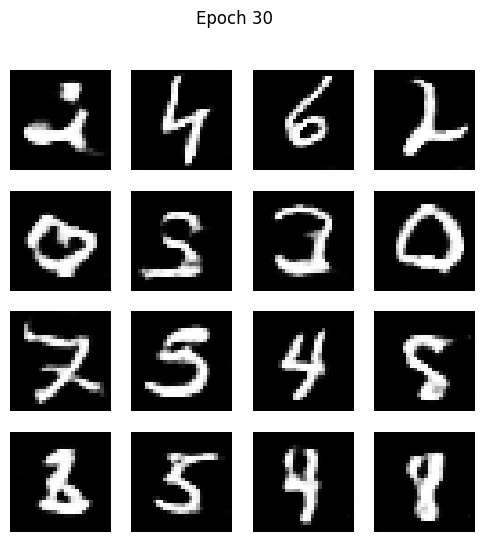

In [ ]:
EPOCHS = 30
NUM_PREVIEW = 16
seed = tf.random.normal([NUM_PREVIEW, LATENT_DIM])   # fixed noise to track progress

@tf.function
def train_step(real_images):
    noise = tf.random.normal([tf.shape(real_images)[0], LATENT_DIM])
    with tf.GradientTape() as g_tape, tf.GradientTape() as d_tape:
        fake_images = generator(noise, training=True)
        real_out = discriminator(real_images, training=True)
        fake_out = discriminator(fake_images, training=True)
        g_loss = generator_loss(fake_out)
        d_loss = discriminator_loss(real_out, fake_out)
    d_grads = d_tape.gradient(d_loss, discriminator.trainable_variables)
    g_grads = g_tape.gradient(g_loss, generator.trainable_variables)
    d_opt.apply_gradients(zip(d_grads, discriminator.trainable_variables))
    g_opt.apply_gradients(zip(g_grads, generator.trainable_variables))
    return g_loss, d_loss

def show_generated(epoch):
    preds = generator(seed, training=False)
    fig = plt.figure(figsize=(6, 6))
    for i in range(NUM_PREVIEW):
        plt.subplot(4, 4, i+1)
        plt.imshow(preds[i, :, :, 0] * 0.5 + 0.5, cmap="gray"); plt.axis("off")
    plt.suptitle(f"Epoch {epoch}")
    plt.show()

g_losses, d_losses = [], []
import time
show_generated(0)
for epoch in range(1, EPOCHS + 1):
    t0 = time.time()
    g_ep, d_ep = [], []
    for batch in train_ds:
        g_l, d_l = train_step(batch)
        g_ep.append(g_l.numpy()); d_ep.append(d_l.numpy())
    g_losses.append(np.mean(g_ep)); d_losses.append(np.mean(d_ep))
    print(f"Epoch {epoch:02d}/{EPOCHS} | G loss: {g_losses[-1]:.4f} | D loss: {d_losses[-1]:.4f} | {time.time()-t0:.1f}s")
    if epoch in (1, 5, 10, 20, EPOCHS):
        show_generated(epoch)

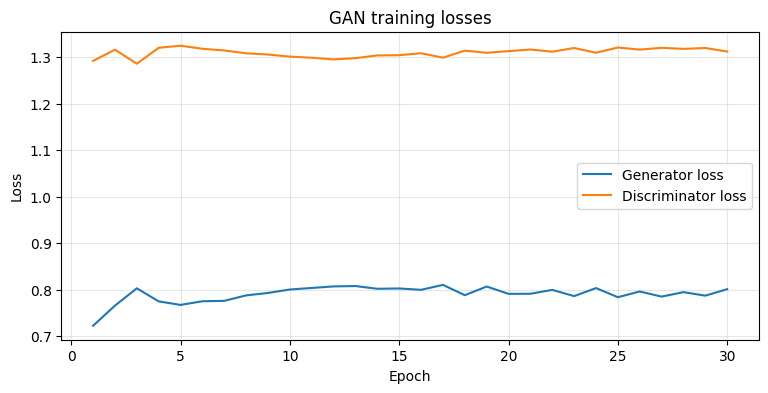

In [ ]:
# Plot losses
plt.figure(figsize=(9, 4))
plt.plot(range(1, EPOCHS+1), g_losses, label="Generator loss")
plt.plot(range(1, EPOCHS+1), d_losses, label="Discriminator loss")
plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.title(f"GAN training losses")
plt.legend(); plt.grid(alpha=0.3); plt.show()

## PART D: Latent-Space Visualization, Generation, Comparison and Experiment Management
> Note: the lab sheet's Part D mentions an LSTM / movie reviews / Encoder, which belong to a different experiment. A plain GAN has no Encoder, so here we (i) generate images from noise, (ii) compare with real data, (iii) interpolate in the latent space, and (iv) use the Discriminator's internal features with PCA / t-SNE for dimensionality reduction and visualization.

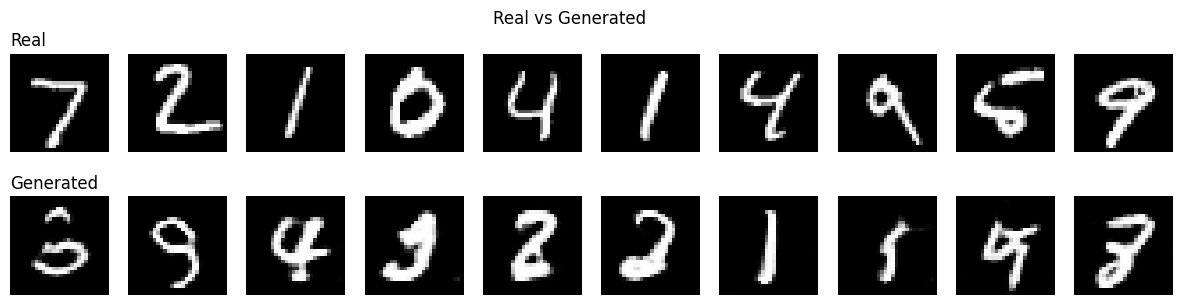

In [ ]:
# 1. Generate new synthetic images and compare with real ones
n = 10
noise = tf.random.normal([n, LATENT_DIM])
fake = generator(noise, training=False).numpy()[:, :, :, 0] * 0.5 + 0.5
real = x_test[:n] / 255.0

fig, axes = plt.subplots(2, n, figsize=(15, 3.4))
for i in range(n):
    axes[0, i].imshow(real[i], cmap="gray"); axes[0, i].axis("off")
    axes[1, i].imshow(fake[i], cmap="gray"); axes[1, i].axis("off")
axes[0, 0].set_title("Real", loc="left"); axes[1, 0].set_title("Generated", loc="left")
plt.suptitle(f"Real vs Generated "); plt.show()

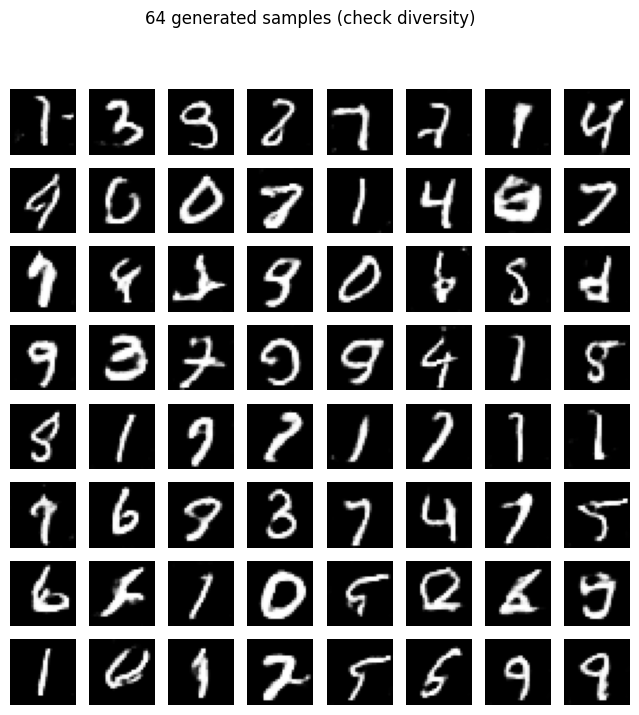

In [ ]:
# 2. Diversity check: a larger grid of generated digits
grid = generator(tf.random.normal([64, LATENT_DIM]), training=False).numpy()[:, :, :, 0] * 0.5 + 0.5
fig, axes = plt.subplots(8, 8, figsize=(8, 8))
for ax, im in zip(axes.flat, grid):
    ax.imshow(im, cmap="gray"); ax.axis("off")
plt.suptitle("64 generated samples (check diversity)"); plt.show()

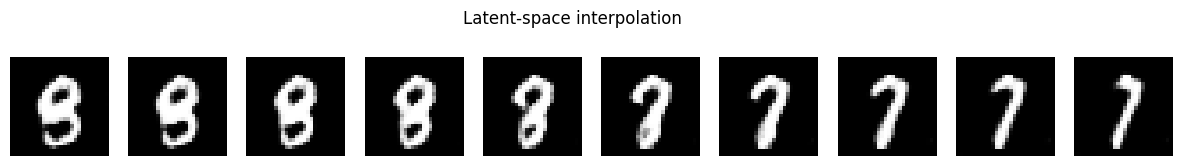

In [ ]:
# 3. Latent-space interpolation between two noise vectors
z1, z2 = tf.random.normal([1, LATENT_DIM]), tf.random.normal([1, LATENT_DIM])
steps = 10
zs = tf.concat([z1 * (1 - a) + z2 * a for a in np.linspace(0, 1, steps)], axis=0)
interp = generator(zs, training=False).numpy()[:, :, :, 0] * 0.5 + 0.5
fig, axes = plt.subplots(1, steps, figsize=(15, 2))
for ax, im in zip(axes, interp):
    ax.imshow(im, cmap="gray"); ax.axis("off")
plt.suptitle("Latent-space interpolation"); plt.show()

/usr/local/lib/python3.13/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: ['keras_tensor_12']
Received: inputs=Tensor(shape=(1000, 28, 28, 1))
  warnings.warn(msg)


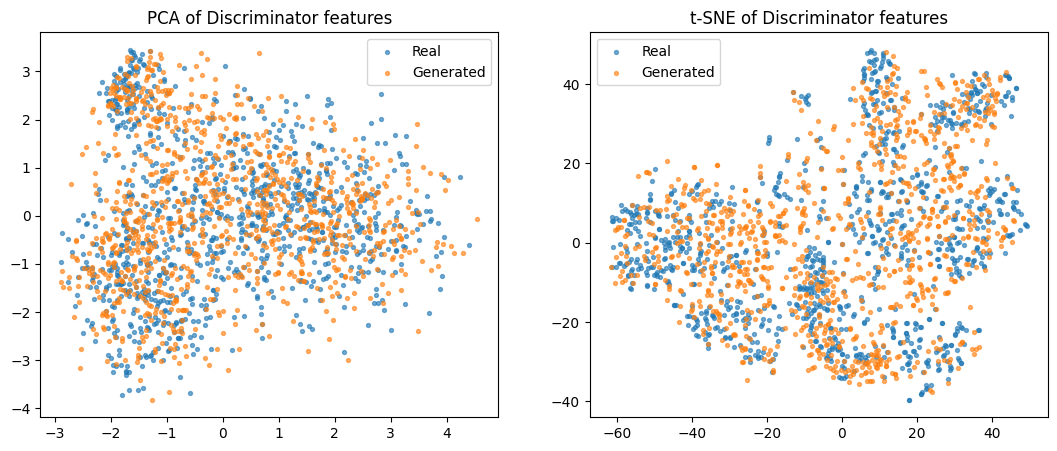

Mean D(real) = 0.516 | Mean D(fake) = 0.454  (values near 0.5 => well-balanced GAN)


In [ ]:
# 4. Dimensionality reduction on Discriminator features (real vs generated)
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

feature_extractor = models.Model(discriminator.inputs, discriminator.layers[-2].output)  # Flatten layer
N = 1000
real_imgs = (x_test[:N].astype("float32") - 127.5) / 127.5
real_imgs = real_imgs.reshape(-1, 28, 28, 1)
fake_imgs = generator(tf.random.normal([N, LATENT_DIM]), training=False)

f_real = feature_extractor(real_imgs, training=False).numpy()
f_fake = feature_extractor(fake_imgs, training=False).numpy()
X = np.vstack([f_real, f_fake]); labels = np.array([0]*N + [1]*N)

X_pca = PCA(n_components=2).fit_transform(X)
X_tsne = TSNE(n_components=2, perplexity=30, random_state=42, init="pca").fit_transform(X)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, data, title in zip(axes, [X_pca, X_tsne], ["PCA", "t-SNE"]):
    ax.scatter(data[labels==0, 0], data[labels==0, 1], s=8, alpha=0.6, label="Real")
    ax.scatter(data[labels==1, 0], data[labels==1, 1], s=8, alpha=0.6, label="Generated")
    ax.set_title(f"{title} of Discriminator features"); ax.legend()
plt.show()

# Discriminator's average belief
d_real = tf.sigmoid(discriminator(real_imgs, training=False)).numpy().mean()
d_fake = tf.sigmoid(discriminator(fake_imgs, training=False)).numpy().mean()
print(f"Mean D(real) = {d_real:.3f} | Mean D(fake) = {d_fake:.3f}  (values near 0.5 => well-balanced GAN)")